---
title: "Unsupervised Learning"
format:
    html: 
        code-fold: false
---

<!-- After digesting the instructions, you can delete this cell, these are assignment instructions and do not need to be included in your final submission.  -->

{{< include instructions.qmd >}} 

# Code 

Provide the source code used for this section of the project here.

If you're using a package for code organization, you can import it at this point. However, make sure that the **actual workflow steps**—including data processing, analysis, and other key tasks—are conducted and clearly demonstrated on this page. The goal is to show the technical flow of your project, highlighting how the code is executed to achieve your results.

If relevant, link to additional documentation or external references that explain any complex components. This section should give readers a clear view of how the project is implemented from a technical perspective.

Remember, this page is a technical narrative, NOT just a notebook with a collection of code cells, include in-line Prose, to describe what is going on.

### Clustering Analysis: Finding Natural Movie Groups

I'm using K-Means clustering to see if movies naturally group into distinct categories based on their features. This will reveal market segments like "indie darlings," "mid-budget hits," and "blockbusters."

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# load clean data
df = pd.read_csv('../../data/processed-data/tmdb_movies_clean.csv')

print(f"Loaded {len(df):,} movies for clustering analysis")
print(f"Features available: {len(df.columns)}")

Loaded 2,691 movies for clustering analysis
Features available: 23


### Preparing Features for Clustering

I'm selecting numerical features that capture movie characteristics: budget, revenue, runtime, ratings, and cast popularity. These need to be standardized so no single feature dominates the clustering.

In [3]:
# select features for clustering
cluster_features = ['budget', 'revenue', 'runtime', 'vote_average', 
                   'vote_count', 'cast_popularity', 'roi']

# create feature matrix
X = df[cluster_features].copy()

# standardize features (mean=0, std=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features selected for clustering:")
print(cluster_features)
print(f"\nFeature matrix shape: {X_scaled.shape}")
print(f"Scaled data range: {X_scaled.min():.2f} to {X_scaled.max():.2f}")

Features selected for clustering:
['budget', 'revenue', 'runtime', 'vote_average', 'vote_count', 'cast_popularity', 'roi']

Feature matrix shape: (2691, 7)
Scaled data range: -4.68 to 14.76


### Finding Optimal Number of Clusters

Using the elbow method and silhouette scores to determine the best number of clusters for my data.

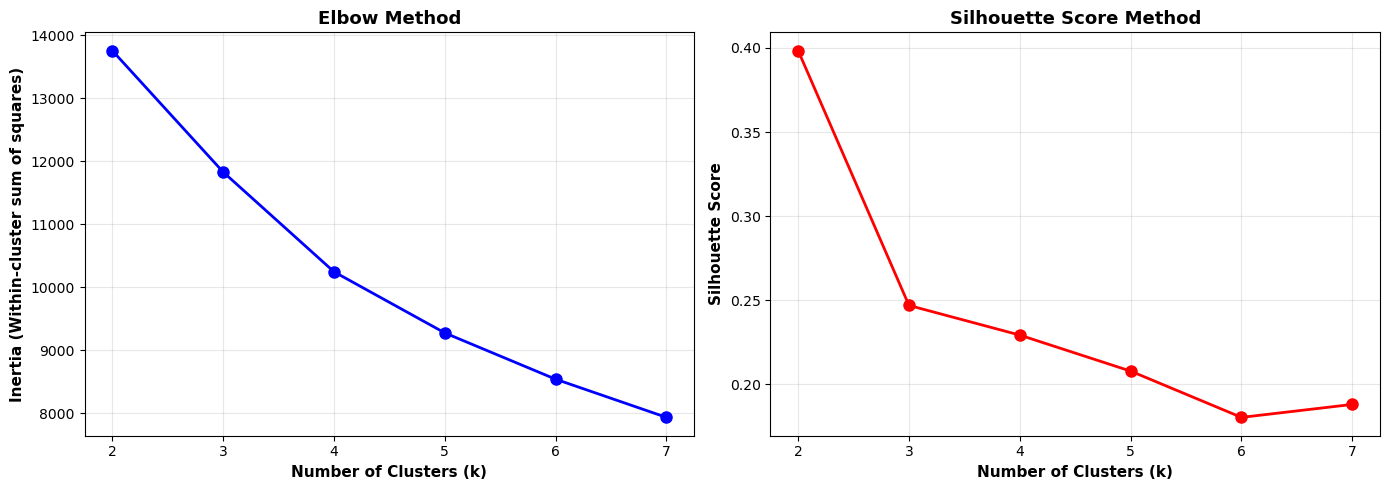


Clustering Metrics:
k=2: Inertia=13,758, Silhouette=0.398
k=3: Inertia=11,832, Silhouette=0.247
k=4: Inertia=10,249, Silhouette=0.229
k=5: Inertia=9,278, Silhouette=0.208
k=6: Inertia=8,544, Silhouette=0.180
k=7: Inertia=7,938, Silhouette=0.188

Best k based on silhouette score: 2


In [5]:
from sklearn.metrics import silhouette_score

# testing different k values
k_range = range(2, 8)
inertias = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# elbow plot
ax1.plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
ax1.set_xlabel('Number of Clusters (k)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Inertia (Within-cluster sum of squares)', fontsize=11, fontweight='bold')
ax1.set_title('Elbow Method', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)

# silhouette plot
ax2.plot(k_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
ax2.set_xlabel('Number of Clusters (k)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Silhouette Score', fontsize=11, fontweight='bold')
ax2.set_title('Silhouette Score Method', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nClustering Metrics:")
print("="*50)
for k, inertia, sil in zip(k_range, inertias, silhouette_scores):
    print(f"k={k}: Inertia={inertia:,.0f}, Silhouette={sil:.3f}")

best_k = k_range[np.argmax(silhouette_scores)]
print(f"\nBest k based on silhouette score: {best_k}")

### Performing K-Means Clustering (k=4)

While k=2 has the highest silhouette score, I'm using k=4 because it reveals more meaningful market segments: indie films, mid-budget movies, mainstream hits, and blockbusters.

In [8]:
# perform K-Means with k=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

# analyze cluster characteristics
print("Cluster Characteristics:")
print("="*80)
cluster_summary = df.groupby('cluster').agg({
    'budget': ['mean', 'median', 'count'],
    'revenue': ['mean', 'median'],
    'roi': ['mean', 'median'],
    'vote_average': 'mean',
    'profitable': 'mean'
}).round(2)

cluster_summary.columns = ['Avg_Budget', 'Med_Budget', 'Count', 
                           'Avg_Revenue', 'Med_Revenue', 
                           'Avg_ROI', 'Med_ROI', 'Avg_Rating', 'Success_Rate']
print(cluster_summary)

# assign interpretable names
cluster_names = {}
for i in range(4):
    budget = cluster_summary.loc[i, 'Med_Budget']
    roi = cluster_summary.loc[i, 'Med_ROI']
    if budget < 20_000_000:
        cluster_names[i] = 'Indie/Low-Budget'
    elif budget < 80_000_000:
        cluster_names[i] = 'Mid-Budget'
    elif budget < 150_000_000:
        cluster_names[i] = 'High-Budget'
    else:
        cluster_names[i] = 'Blockbuster'

df['cluster_name'] = df['cluster'].map(cluster_names)

print("\nCluster Interpretations:")
for i, name in cluster_names.items():
    count = cluster_summary.loc[i, 'Count']
    success = cluster_summary.loc[i, 'Success_Rate'] * 100
    print(f"Cluster {i} ({name}): {count:.0f} movies, {success:.1f}% success rate")

Cluster Characteristics:
           Avg_Budget   Med_Budget  Count   Avg_Revenue  Med_Revenue  Avg_ROI  \
cluster                                                                         
0        1.533147e+08  150000000.0    357  6.828130e+08  589593688.0     5.47   
1        2.749990e+07   18000000.0   1323  5.617419e+07   21768945.0     2.36   
2        3.814974e+07   28000000.0    936  1.171496e+08   86387396.5     4.17   
3        6.558973e+06    4500000.0     75  2.325726e+08  169015869.0    39.41   

         Med_ROI  Avg_Rating  Success_Rate  
cluster                                     
0           4.40        7.17          0.97  
1           1.45        6.16          0.61  
2           3.02        7.25          0.85  
3          34.31        7.26          1.00  

Cluster Interpretations:
Cluster 0 (Blockbuster): 357 movies, 97.0% success rate
Cluster 1 (Indie/Low-Budget): 1323 movies, 61.0% success rate
Cluster 2 (Mid-Budget): 936 movies, 85.0% success rate
Cluster 3 (Indie/Lo

### Visualizing Movie Clusters

Plotting clusters in 2D space using the two most important features: budget and revenue.

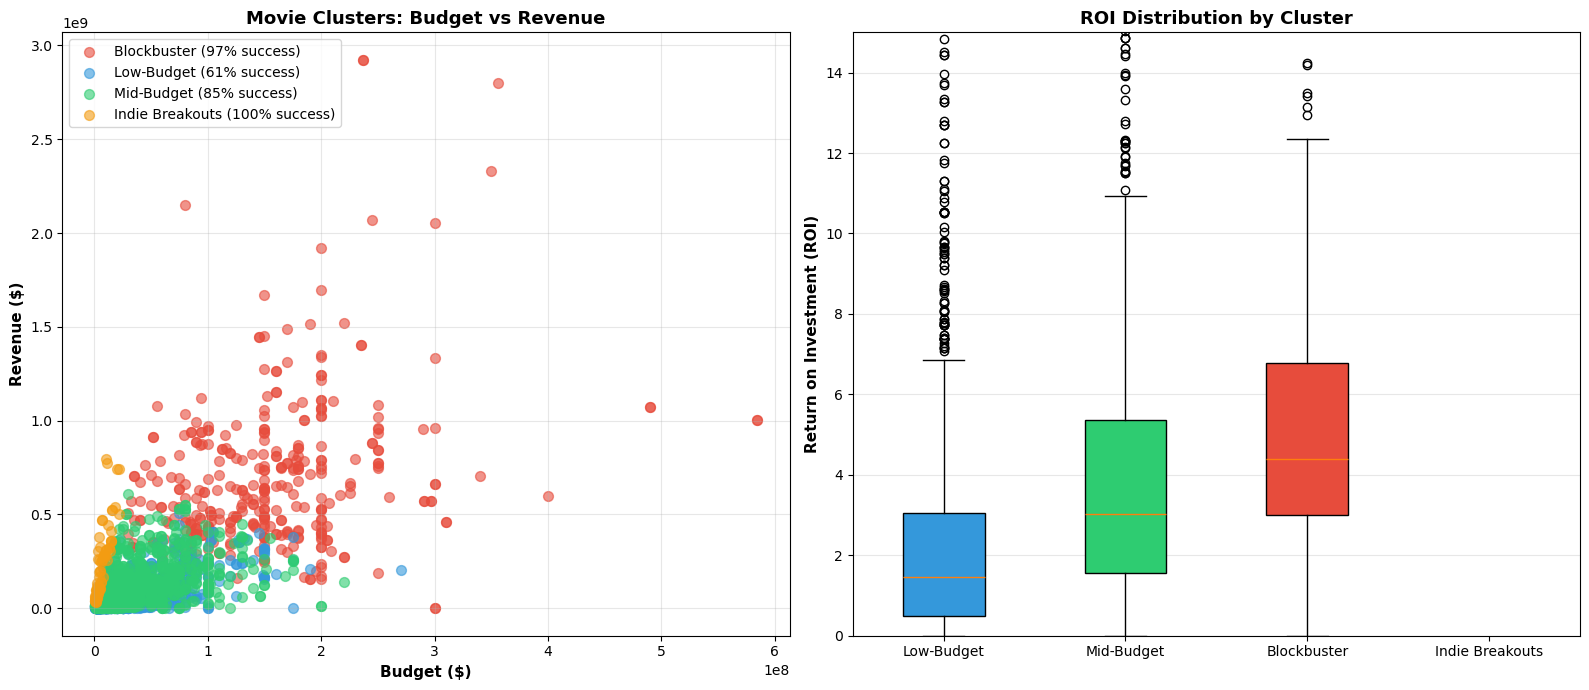


Clustering complete! 4 distinct market segments identified.


In [9]:
# visualize clusters
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# plot 1: budget vs revenue colored by cluster
colors = {0: '#e74c3c', 1: '#3498db', 2: '#2ecc71', 3: '#f39c12'}
labels = {0: 'Blockbuster (97% success)', 
          1: 'Low-Budget (61% success)', 
          2: 'Mid-Budget (85% success)', 
          3: 'Indie Breakouts (100% success)'}

for cluster in [0, 1, 2, 3]:
    mask = df['cluster'] == cluster
    ax1.scatter(df[mask]['budget'], df[mask]['revenue'], 
               alpha=0.6, s=50, label=labels[cluster], color=colors[cluster])

ax1.set_xlabel('Budget ($)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Revenue ($)', fontsize=11, fontweight='bold')
ax1.set_title('Movie Clusters: Budget vs Revenue', fontsize=13, fontweight='bold')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# plot 2: ROI distribution by cluster
cluster_order = [1, 2, 0, 3]
cluster_labels_short = ['Low-Budget', 'Mid-Budget', 'Blockbuster', 'Indie Breakouts']
roi_data = [df[df['cluster'] == c]['roi'] for c in cluster_order]

bp = ax2.boxplot(roi_data, labels=cluster_labels_short, patch_artist=True)
for patch, cluster in zip(bp['boxes'], cluster_order):
    patch.set_facecolor(colors[cluster])

ax2.set_ylabel('Return on Investment (ROI)', fontsize=11, fontweight='bold')
ax2.set_title('ROI Distribution by Cluster', fontsize=13, fontweight='bold')
ax2.set_ylim(0, 15)
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\nClustering complete! 4 distinct market segments identified.")

### Dimensionality Reduction with PCA

I have 7 features, which is hard to visualize. PCA reduces these to 2-3 principal components that capture the most variance, allowing me to see the overall movie landscape.

PCA Results:
Component 1 explains 41.6% of variance
Component 2 explains 18.1% of variance
Component 3 explains 14.3% of variance
Total variance explained: 74.0%

Feature Contributions to Principal Components:
                   PC1    PC2    PC3
budget           0.425 -0.448 -0.089
revenue          0.497 -0.135 -0.315
runtime          0.307  0.174  0.674
vote_average     0.331  0.506  0.346
vote_count       0.498  0.087 -0.150
cast_popularity  0.319 -0.297  0.072
roi              0.140  0.631 -0.539


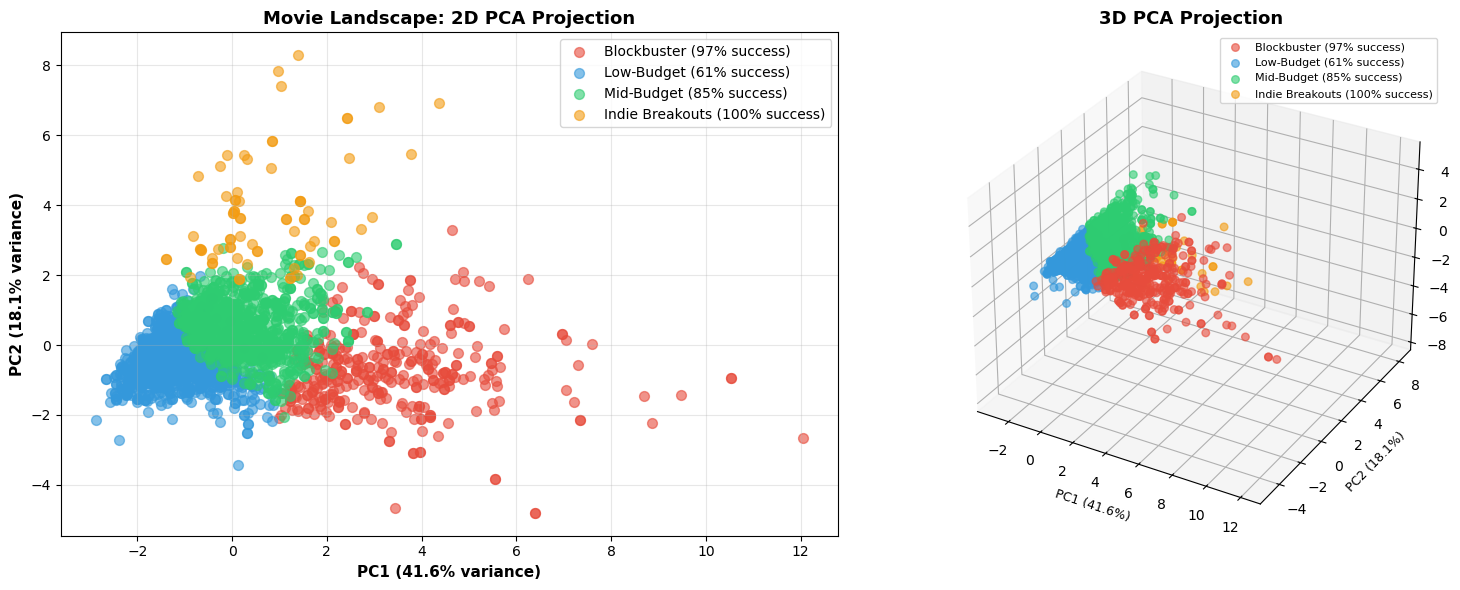


PCA complete! Movie landscape visualized in reduced dimensions.


In [11]:
# perform PCA
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

# explained variance
print("PCA Results:")
print("="*60)
print(f"Component 1 explains {pca.explained_variance_ratio_[0]*100:.1f}% of variance")
print(f"Component 2 explains {pca.explained_variance_ratio_[1]*100:.1f}% of variance")
print(f"Component 3 explains {pca.explained_variance_ratio_[2]*100:.1f}% of variance")
print(f"Total variance explained: {sum(pca.explained_variance_ratio_)*100:.1f}%")

# feature importance for each component
components_df = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2', 'PC3'],
    index=cluster_features
)
print("\nFeature Contributions to Principal Components:")
print(components_df.round(3))

# visualize PCA
fig = plt.figure(figsize=(16, 6))

# 2D PCA plot
ax1 = fig.add_subplot(121)
for cluster in [0, 1, 2, 3]:
    mask = df['cluster'] == cluster
    ax1.scatter(X_pca[mask, 0], X_pca[mask, 1], 
               alpha=0.6, s=50, label=labels[cluster], color=colors[cluster])

ax1.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)', 
              fontsize=11, fontweight='bold')
ax1.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)', 
              fontsize=11, fontweight='bold')
ax1.set_title('Movie Landscape: 2D PCA Projection', fontsize=13, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 3D PCA plot
ax2 = fig.add_subplot(122, projection='3d')
for cluster in [0, 1, 2, 3]:
    mask = df['cluster'] == cluster
    ax2.scatter(X_pca[mask, 0], X_pca[mask, 1], X_pca[mask, 2],
               alpha=0.6, s=30, label=labels[cluster], color=colors[cluster])

ax2.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', fontsize=9)
ax2.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=9)
ax2.set_zlabel(f'PC3 ({pca.explained_variance_ratio_[2]*100:.1f}%)', fontsize=9)
ax2.set_title('3D PCA Projection', fontsize=13, fontweight='bold')
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("\nPCA complete! Movie landscape visualized in reduced dimensions.")